# **Sesión 4:** Procesamiento de imagenes y extracción de características

## **Librerías**

In [1]:
import cv2
import os
import matplotlib.pyplot as plt

## **Apartado A:** Detección de lineas rectas
El objetivo de este apartado es la detección de líneas y bordes en las imágenes de la carpeta `data/partA`.
1. **Tarea A.1.** Aplique `cv2.Canny()` a las imágenes de trabajo ajustando los hiperparámetros.
3. **Tarea A.2.** Implemente la función `draw_lines()` para pintar las líneas sobre las imágenes.
4. **Tarea A.3.** Aplique Hough con `cv2.HoughLinesP()` a las imágenes de trabajo para extraer líneas y afine los hiperparámetros.
5. **Problema A.1.** Repita el procedimiento para extraer las líneas de las dos imágenes restantes.

### **NOTA**
Podéis usar el mismo formato de guardado de resultados y nomenclatura que en en las práctica 3 o hacer uso de la funcion `show_image()` del Lab 1. Usad las herramientas con las que os sintáis más cómodos

In [2]:
# Nos definimos estas funciones auxiliares que nos facilitará algunas tareas más adelante

from rpds import List
import numpy as np

def show_image(img: np.array, img_name: str = "Image"):
    cv2.imshow(img_name, img)  # Mostramos la imagen, poniendole el nombre correspondiente a la ventana desplegada
    cv2.waitKey(0)  # Ponemos una tecla para eliminar la ventana y pasar a la siguiente imagen o terminar la visualización
    cv2.destroyAllWindows()

def load_images(filenames: List) -> List:
    return [cv2.imread(filename) for filename in filenames]

def write_image(output_folder: str, img_name: str, img: np.array):
    img_path = os.path.join(output_folder, img_name)  # creamos el path donde vamos a guardar la imagen
    os.makedirs(output_folder, exist_ok=True)
    cv2.imwrite(img_path, img)  # guardamos la imagen en su correspondiente ubicación

In [3]:
# Cargamos las imágenes correspondientes al apartado A de la práctica

import glob

imgs_gen_path = '../data/partA/*' # Patrón que cumplen todos los paths de los archivos de imágenes de la carpeta data/partA
imgs_path = sorted(glob.glob(imgs_gen_path))  # Cogemos todos los paths que cumplen ese patrón genérico (usando glob) y los ordenamos (usando sorted)
imgs = load_images(imgs_path)  # Le pasamos a load_images la lista de paths o filenames de las imágenes que queremos cargar

imgs_path


['../data/partA\\0.jpg',
 '../data/partA\\1.png',
 '../data/partA\\2.png',
 '../data/partA\\3.png']

### **Tarea A.1.** Aplique `cv2.Canny()` a las imágenes de trabajo ajustando los hiperparámetros

In [4]:
# TODO Apply canny to the images, play with the thresholds to get a good result

edge_imgs = []  # to store the canny edge images for later Hough transform

# 1st image

# Hyperparameters
low_threshold = 30
high_threshold = 180

# get the first image
img = imgs[0]

# Convert to grayscale
gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Apply Canny edge detection
edge_img = cv2.Canny(gray_img, low_threshold, high_threshold)

# Store the edge image for later Hough transform
edge_imgs.append(edge_img)

# Display the image or save it as you like
show_image(edge_img, "Canny Edge Image 1")

# 2nd image
img = imgs[1]

# Convert to grayscale
gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Apply Canny edge detection
edge_img = cv2.Canny(gray_img, low_threshold, high_threshold)

# Store the edge image for later Hough transform
edge_imgs.append(edge_img)

# Display the image or save it as you like
show_image(edge_img, "Canny Edge Image 2")

for img in imgs[2:]:
    # Convert to grayscale
    gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Apply Canny edge detection
    edge_img = cv2.Canny(gray_img, low_threshold, high_threshold)

    # Store the edge image for later Hough transform
    edge_imgs.append(edge_img)

### Probamos distintos valores de los hiperparámetros de límite inferior y superior para el threshold de Canny

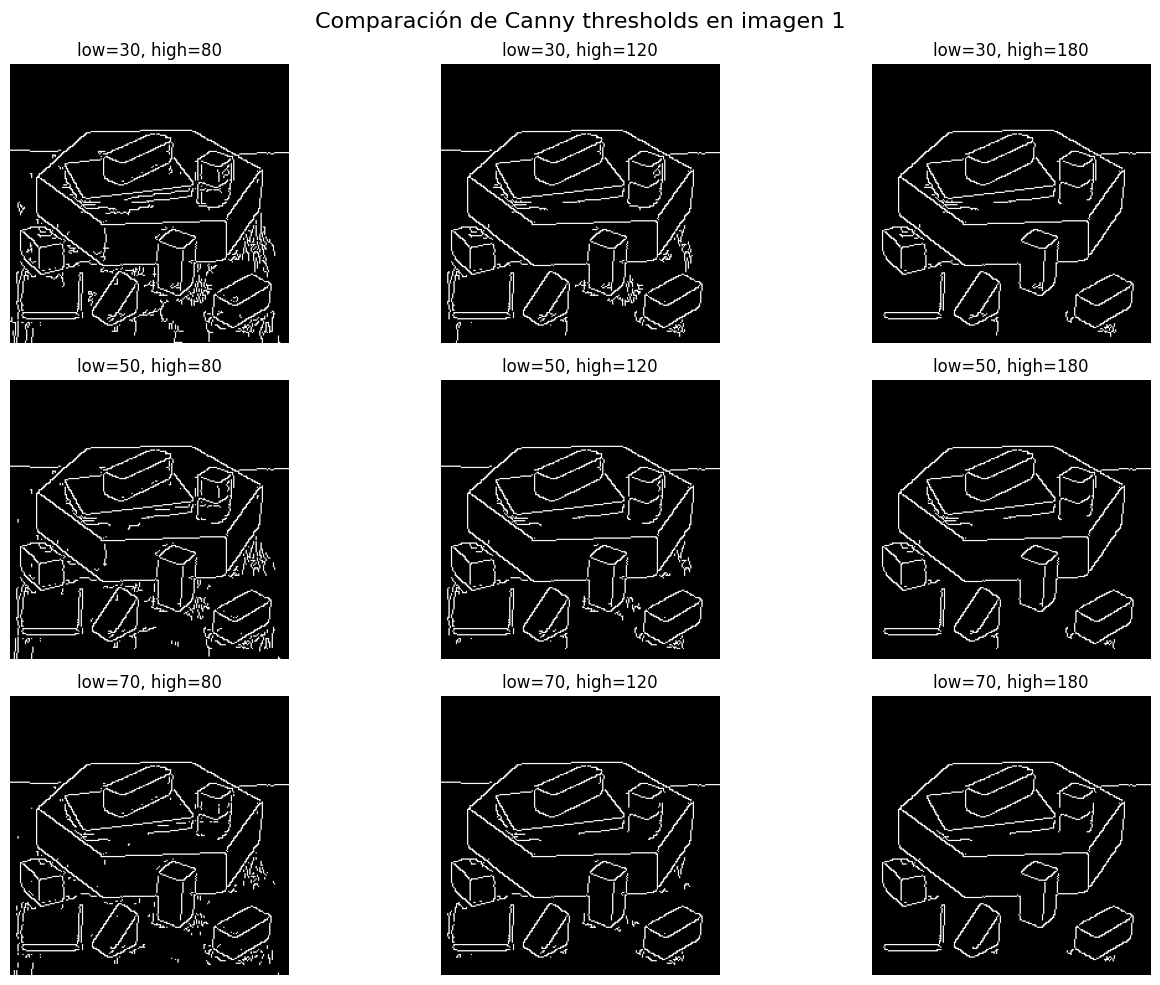

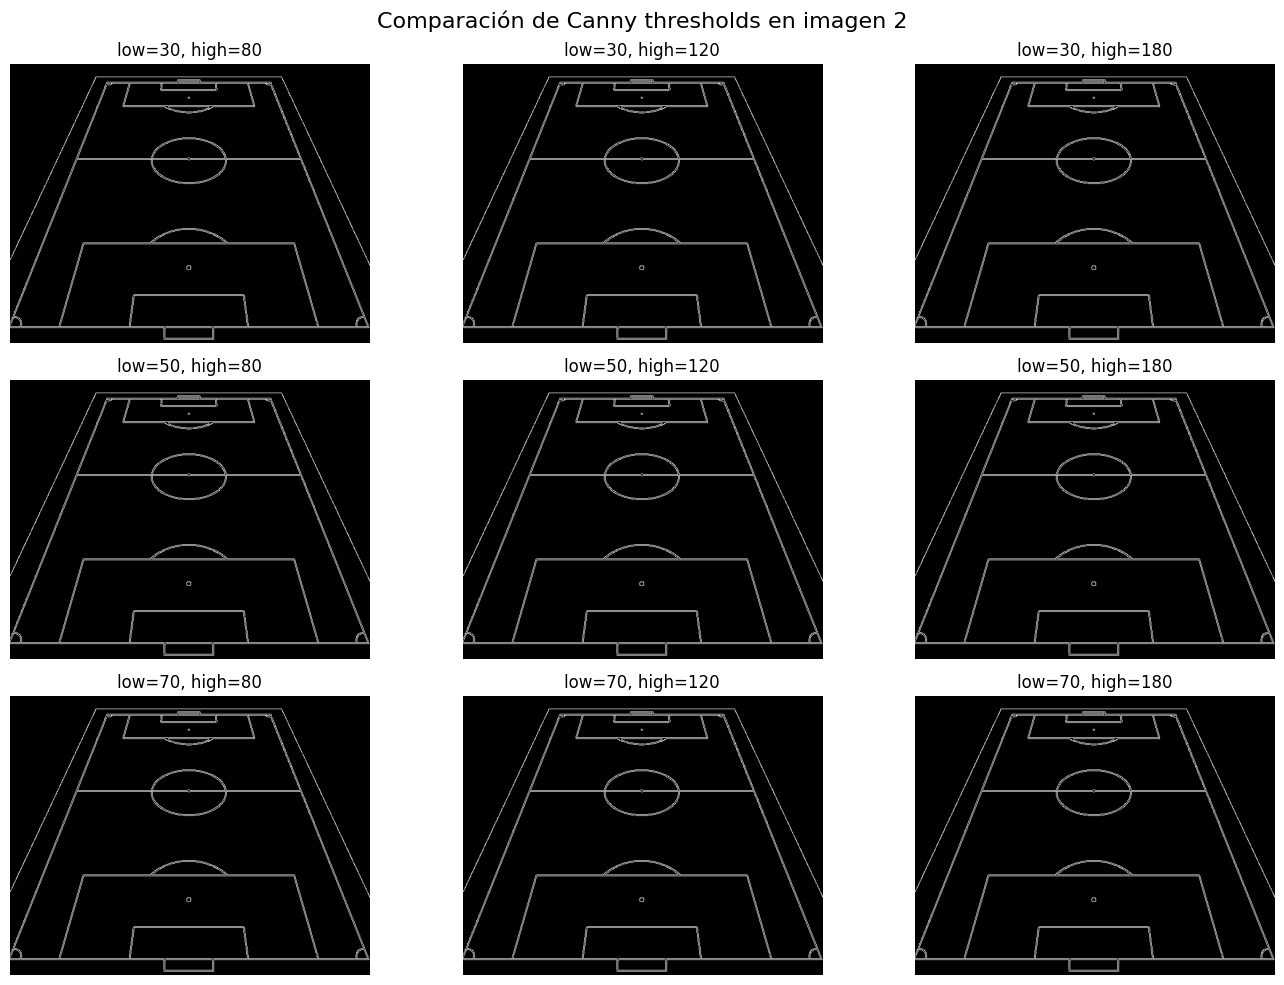

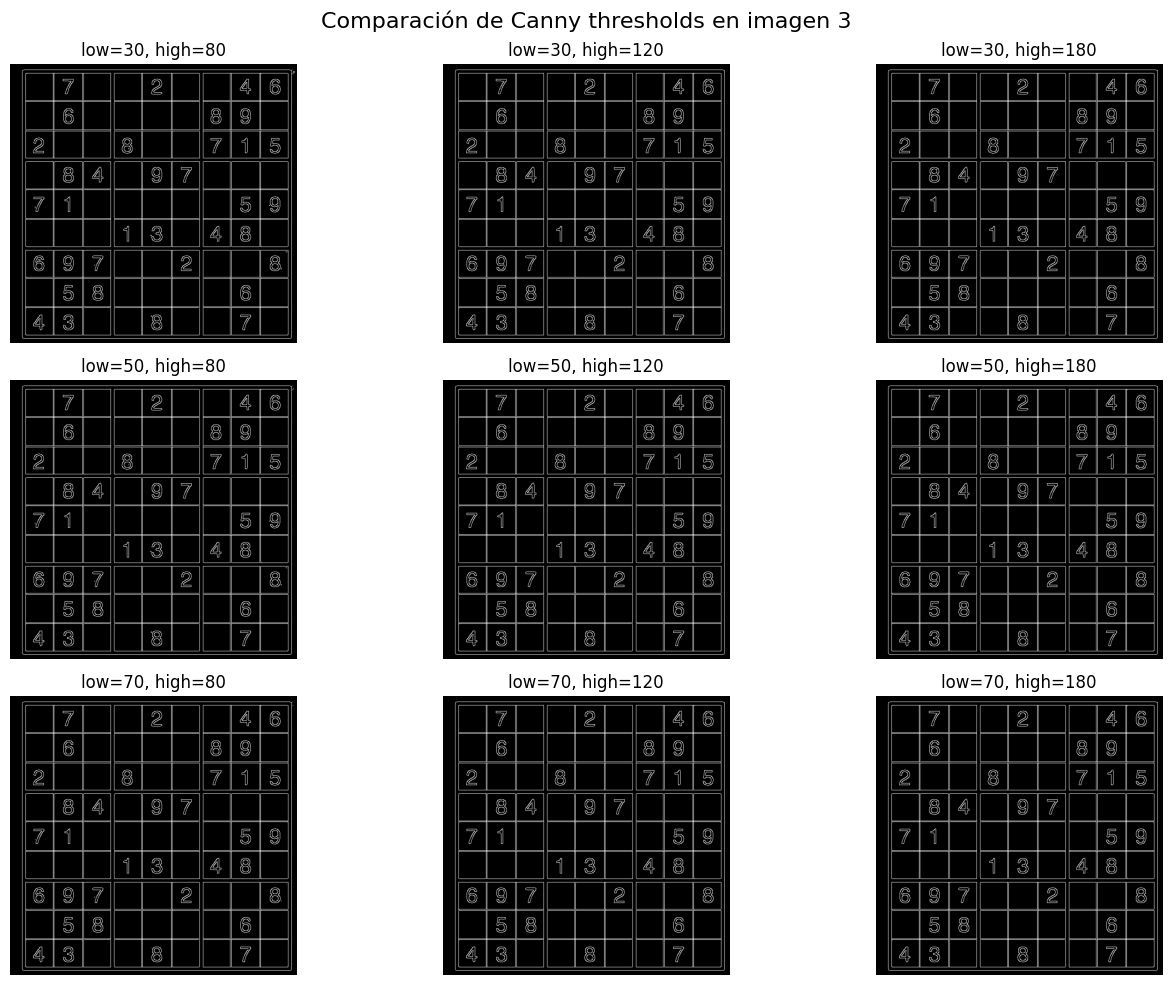

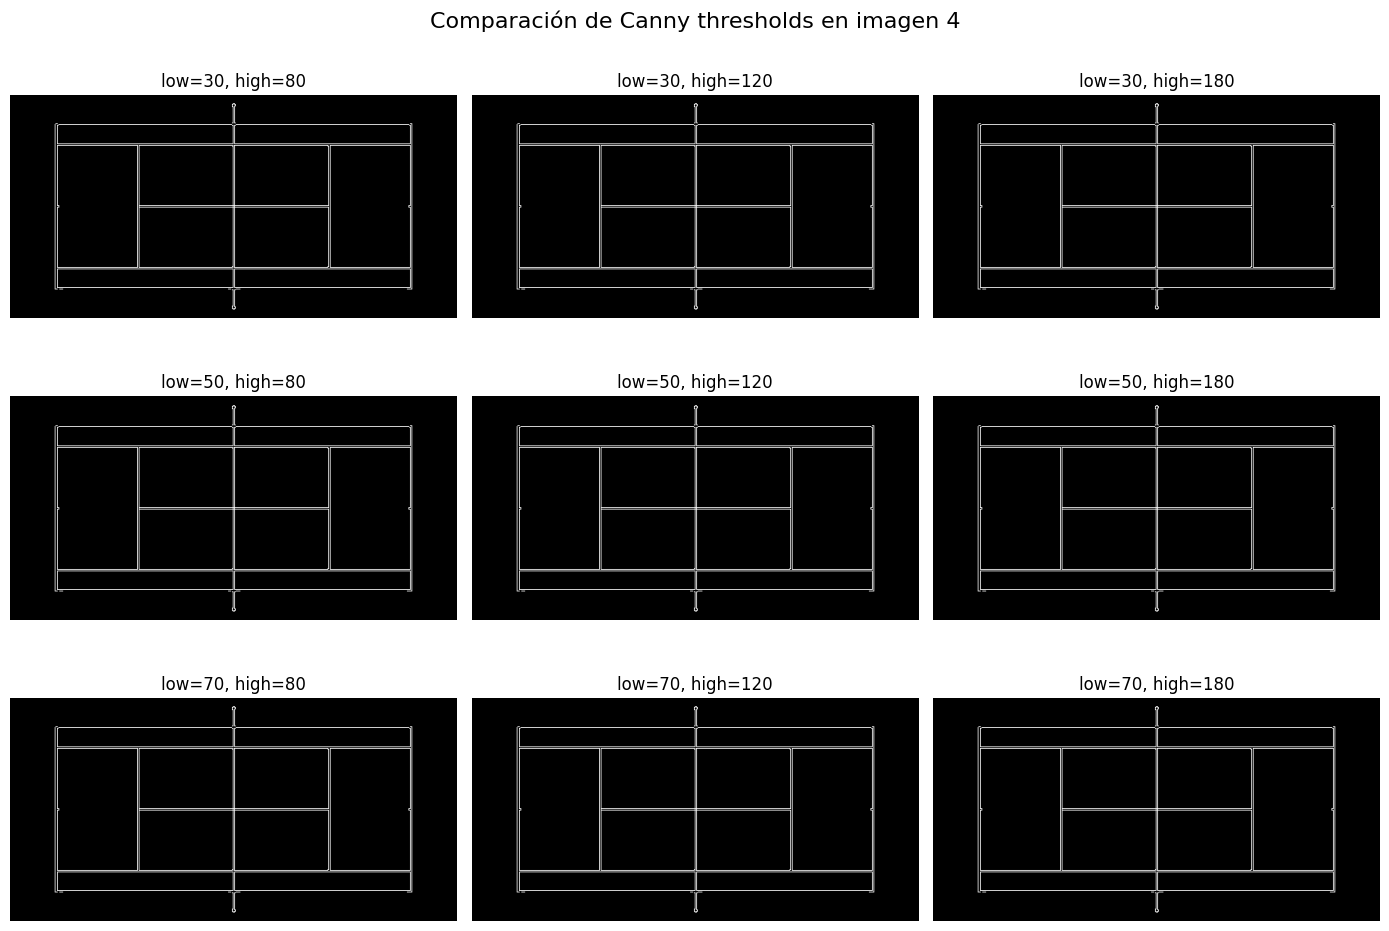

In [5]:
# -----------------------------
# VALORES A PROBAR
# -----------------------------

low_values  = [30, 50, 70]
high_values = [80, 120, 180]

num_imgs = len(imgs)

# Para cada imagen queremos una figura
for idx, img in enumerate(imgs):

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    fig, axes = plt.subplots(len(low_values), len(high_values), figsize=(14, 10))
    fig.suptitle(f"Comparación de Canny thresholds en imagen {idx+1}", fontsize=16)

    for i, low in enumerate(low_values):
        for j, high in enumerate(high_values):

            # IMPORTANTE: solo mostramos combinaciones válidas
            if high <= low:  
                axes[i, j].set_title(f"low={low}, high={high}\n(high <= low: inválido)")
                axes[i, j].axis("off")
                continue

            # Aplicamos Canny
            edge = cv2.Canny(gray, low, high)

            # Mostramos el resultado
            axes[i, j].imshow(edge, cmap="gray")
            axes[i, j].set_title(f"low={low}, high={high}")
            axes[i, j].axis("off")

    plt.tight_layout()
    plt.show()



El detector de bordes de Canny utiliza dos umbrales, low_threshold y high_threshold, que controlan cómo se clasifican los gradientes de la imagen como bordes reales o ruido. El funcionamiento del algoritmo se basa en una doble umbralización: los gradientes mayores que high_threshold se consideran bordes fuertes de forma automática, mientras que los gradientes entre low_threshold y high_threshold se consideran bordes débiles y solo se mantienen si están conectados a un borde fuerte. Los gradientes por debajo de low_threshold se descartan completamente.

Cuando se modifican estos umbrales, la detección de bordes cambia de forma significativa:

Un low_threshold bajo hace que prácticamente cualquier variación de intensidad se considere borde débil. Esto genera un mapa de bordes más denso, pero también más ruidoso, con líneas irrelevantes y discontinuidades. Un low_threshold alto, en cambio, elimina muchos bordes débiles y solo conserva los de mayor contraste, lo que produce mapas más limpios pero menos detallados, pudiendo perder contornos finos.

Respecto al high_threshold, si se elige un valor bajo, muchos bordes pasan a clasificarse como bordes fuertes. Esto hace que la imagen resultante muestre numerosos bordes aceptados, incluso algunos que no deberían considerarse estructurales. Si se fija un high_threshold elevado, únicamente los gradientes muy intensos generan bordes fuertes, de modo que el resultado contiene líneas muy claras y definidas, pero pierde gran parte de la estructura secundaria de la escena.

El equilibrio entre ambos umbrales determina la calidad del resultado: una diferencia pequeña entre low y high genera un mapa de bordes muy restrictivo, mientras que una diferencia grande permite mantener bordes débiles conectados a bordes fuertes, lo que mejora la continuidad de los contornos. En la práctica, valores moderados y una relación aproximada de high_threshold ≈ 2 · low_threshold suelen proporcionar mapas de bordes limpios, continuos y adecuados para pasos posteriores como la transformada de Hough.

No obstante, pese a todo lo comentado, las diferencias notables entre las distinttas combinaciones de hiperparámetros, tan solo se perciben en este caso cuando aplicamos dichas combinaciones de valores de thresholds a la imagen 1 de las formas geométricas. 

---

En la comparación visual de la primera imagen se aprecia cómo los valores de low_threshold y high_threshold influyen directamente en la densidad, continuidad y limpieza de los bordes extraídos por el detector de Canny. Para low_threshold = 30, los mapas de bordes contienen gran cantidad de bordes débiles y ruido, especialmente en las zonas de textura del fondo y en las aristas menos contrastadas de los bloques; al combinarlo con un high_threshold bajo como 80 la imagen se vuelve especialmente ruidosa, mientras que un high_threshold mayor (120 o 180) reduce ligeramente el ruido, aunque siguen apareciendo contornos muy densos.

Cuando low_threshold aumenta a 50, la cantidad de ruido disminuye notablemente: los bordes finos o débiles empiezan a desaparecer y se conservan principalmente las aristas más claras de los objetos. El patrón se mantiene: high_threshold = 80 produce más detalles, aunque con algo de ruido, mientras que high_threshold = 180 genera un esquema de bordes más limpio pero con pérdida de algunas líneas finas de la escena.

Finalmente, con low_threshold = 70 el detector se vuelve aún más selectivo y solo aparecen bordes con gradientes relativamente fuertes. Las líneas resultan más definidas y limpias en todas las combinaciones, pero también se pierde información estructural: algunas aristas internas de los bloques o detalles del fondo ya no se detectan. De nuevo, high_threshold = 180 produce el resultado más minimalista y depurado, mientras que high_threshold = 80 conserva algunos bordes adicionales.

En conjunto, la figura muestra cómo unos umbrales bajos generan detecciones ruidosas y muy densas, mientras que umbrales altos producen mapas más limpios pero con pérdida de detalle. La elección óptima depende del equilibrio deseado entre sensibilidad y precisión según el tipo de escena y el objetivo final (por ejemplo, si se va a aplicar una transformada de Hough interesa evitar ruido excesivo).

### **Tarea A.2.** Implemente `draw_lines()` para pintar las lineas sobre cada imagen

In [6]:
# TODO Draw the lines on the images. A line is a tuple of 4 integers (x1, y1, x2, y2) where (x1, y1) and (x2, y2) are the coordinates of the two points of the line.
def draw_lines(img, lines, color, thickness):

    # Iteramos por cada una de las líneas detectadas
    for line in lines:
        # Extraemos las coordenadas x,y de los 2 puntos que definen la línea
        x1, y1, x2, y2 = line[0]
        # Pintamos la línea sobre la imnagen, sobreescribiéndola
        cv2.line(img, (x1, y1), (x2, y2), color, thickness)

### **Tarea A.3.** Aplique Hough con `cv2.HoughLinesP()` a las imágenes de trabajo para extraer líneas y afine los hiperparámetros

### Primera Iteración 1º Imagen

In [7]:
# 1st image

# TODO Apply the hough transform to the images, play with the parameters to get a good result

# Hacemos una copia de las imágenes originales ya que al pintar sobre ellas las estaremos sobreescribiendo
new_imgs1 = load_images(imgs_path)

rho = 1
theta = np.pi/180
threshold = 1
min_line_length = 10
max_line_gap = 10

# Get the edge image
edges1 = edge_imgs[0]

show_image(new_imgs1[0])

# Apply the hough transform
lines = cv2.HoughLinesP(edges1, rho, theta, threshold, minLineLength=min_line_length, maxLineGap=max_line_gap)

# Draw the lines on the image (on the original image, make sure to get a copy, as draw_lines modifies the image)
draw_lines(new_imgs1[0], lines, (0, 255, 0), 2)

# Show the image or save it as you like
show_image(new_imgs1[0], "Hough Lines Image 1")


### Segunda Iteración 1º Imagen

In [8]:
# 1st image

# Hacemos una copia de las imágenes originales ya que al pintar sobre ellas las estaremos sobreescribiendo
new_imgs2 = load_images(imgs_path)

rho = 5
theta = np.pi/180
threshold = 1
min_line_length = 10
max_line_gap = 2

# Get the edge image
edges1 = edge_imgs[0]

show_image(new_imgs2[0])

# Apply the hough transform
lines = cv2.HoughLinesP(edges1, rho, theta, threshold, minLineLength=min_line_length, maxLineGap=max_line_gap)

# Draw the lines on the image (on the original image, make sure to get a copy, as draw_lines modifies the image)
draw_lines(new_imgs2[0], lines, (0, 255, 0), 2)

# Show the image or save it as you like
show_image(new_imgs2[0], "Hough Lines Image 1")


### Definitiva 1º Imagen

In [9]:
# 1st image

# Hacemos una copia de las imágenes originales ya que al pintar sobre ellas las estaremos sobreescribiendo
new_imgs3 = load_images(imgs_path)

rho = 1
theta = np.pi/180
threshold = 25
min_line_length = 5
max_line_gap = 5

# Get the edge image
edges1 = edge_imgs[0]

show_image(new_imgs3[0])


# Apply the hough transform
lines = cv2.HoughLinesP(edges1, rho, theta, threshold, minLineLength=min_line_length, maxLineGap=max_line_gap)

# Draw the lines on the image (on the original image, make sure to get a copy, as draw_lines modifies the image)
draw_lines(new_imgs3[0], lines, (0, 255, 0), 2)

# Show the image or save it as you like
show_image(new_imgs3[0], "Hough Lines Image 1")


### Primera Iteración 2º Imagen

In [10]:
# 2nd image

# Hacemos una copia de las imágenes originales ya que al pintar sobre ellas las estaremos sobreescribiendo
new_imgs1 = load_images(imgs_path)

rho = 1
theta = np.pi/180
threshold = 100
min_line_length = 1
max_line_gap = 1

# Get the edge image
edges2 = edge_imgs[1]

show_image(new_imgs1[1])

# Apply the hough transform
lines = cv2.HoughLinesP(edges2, rho, theta, threshold, minLineLength=min_line_length, maxLineGap=max_line_gap)

# Draw the lines on the image (on the original image, make sure to get a copy, as draw_lines modifies the image)
draw_lines(new_imgs1[1], lines, (0, 255, 0), 2)

# Show the image or save it as you like
show_image(new_imgs1[1], "Hough Lines Image 2")

### Segunda Iteración 2º Imagen

In [11]:
# 2nd image

# Hacemos una copia de las imágenes originales ya que al pintar sobre ellas las estaremos sobreescribiendo
new_imgs2 = load_images(imgs_path)

rho = 1
theta = np.pi/180
threshold = 5
min_line_length = 10
max_line_gap = 5

# Get the edge image
edges2 = edge_imgs[1]

show_image(new_imgs2[1])

# Apply the hough transform
lines = cv2.HoughLinesP(edges2, rho, theta, threshold, minLineLength=min_line_length, maxLineGap=max_line_gap)

# Draw the lines on the image (on the original image, make sure to get a copy, as draw_lines modifies the image)
draw_lines(new_imgs2[1], lines, (0, 255, 0), 2)

# Show the image or save it as you like
show_image(new_imgs2[1], "Hough Lines Image 2")

### Definitiva 2º Imagen

In [12]:
# 2nd image

# Hacemos una copia de las imágenes originales ya que al pintar sobre ellas las estaremos sobreescribiendo
new_imgs3 = load_images(imgs_path)

# Estos parámetros los hemos elegido tras hacer múltiples pruebas y conseguir afinarlos bien
rho = 1
theta = np.pi/180
threshold = 15
min_line_length = 10
max_line_gap = 5

# Get the edge image
edges2 = edge_imgs[1]

show_image(new_imgs3[1])

# Apply the hough transform
lines = cv2.HoughLinesP(edges2, rho, theta, threshold, minLineLength=min_line_length, maxLineGap=max_line_gap)

# Draw the lines on the image (on the original image, make sure to get a copy, as draw_lines modifies the image)
draw_lines(new_imgs3[1], lines, (0, 255, 0), 2)

# Show the image or save it as you like
show_image(new_imgs3[1], "Hough Lines Image 2")

### **Problema A.1.** Repita el procedimiento para extraer las líneas de las dos imágenes restantes

### Primera Iteración 3º Imagen

In [13]:
# Hacemos una copia de las imágenes originales ya que al pintar sobre ellas las estaremos sobreescribiendo
new_imgs = imgs.copy()  

In [14]:
# TODO Homework

# 3rd image

# Hacemos una copia de las imágenes originales ya que al pintar sobre ellas las estaremos sobreescribiendo
new_imgs2 = load_images(imgs_path)

rho = 1
theta = np.pi/90
threshold = 20
min_line_length = 5
max_line_gap = 10

# Get the edge image
edges2 = edge_imgs[2]

show_image(new_imgs2[2])


# Apply the hough transform
lines = cv2.HoughLinesP(edges2, rho, theta, threshold, minLineLength=min_line_length, maxLineGap=max_line_gap)

# Draw the lines on the image (on the original image, make sure to get a copy, as draw_lines modifies the image)
draw_lines(new_imgs2[2], lines, (0, 255, 0), 2)

# Show the image or save it as you like
show_image(new_imgs2[2], "Hough Lines Image 3")


### Segunda Iteración 3º Imagen

In [15]:
# Hacemos una copia de las imágenes originales ya que al pintar sobre ellas las estaremos sobreescribiendo
new_imgs3 = load_images(imgs_path)

# Estos parámetros los hemos elegido tras hacer múltiples pruebas y conseguir afinarlos bien
rho = 1
theta = np.pi/180
threshold = 45
min_line_length = 0.01
max_line_gap = 10

# Get the edge image
edges2 = edge_imgs[2]

show_image(new_imgs3[2])


# Apply the hough transform
lines = cv2.HoughLinesP(edges2, rho, theta, threshold, minLineLength=min_line_length, maxLineGap=max_line_gap)

# Draw the lines on the image (on the original image, make sure to get a copy, as draw_lines modifies the image)
draw_lines(new_imgs3[2], lines, (0, 255, 0), 2)

# Show the image or save it as you like
show_image(new_imgs3[2], "Hough Lines Image 3")

### Definitiva 3º Imagen

In [16]:
# 3rd image

# Hacemos una copia de las imágenes originales ya que al pintar sobre ellas las estaremos sobreescribiendo
new_imgs1 = load_images(imgs_path)

rho = 2
theta = np.pi/180
threshold = 300
min_line_length = 1
max_line_gap = 100

# Get the edge image
edges2 = edge_imgs[2]

show_image(new_imgs1[2])

# Apply the hough transform
lines = cv2.HoughLinesP(edges2, rho, theta, threshold, minLineLength=min_line_length, maxLineGap=max_line_gap)

# Draw the lines on the image (on the original image, make sure to get a copy, as draw_lines modifies the image)
draw_lines(new_imgs1[2], lines, (0, 255, 0), 2)

# Show the image or save it as you like
show_image(new_imgs1[2], "Hough Lines Image 3")


### Primera Iteración 4º Imagen

In [17]:
# 4th image

# Hacemos una copia de las imágenes originales ya que al pintar sobre ellas las estaremos sobreescribiendo
new_imgs1 = load_images(imgs_path)

rho = 1
theta = np.pi/180
threshold = 45
min_line_length = 10
max_line_gap = 10

# Get the edge image
edges3 = edge_imgs[3]

show_image(new_imgs1[3])

# Apply the hough transform
lines = cv2.HoughLinesP(edges3, rho, theta, threshold, minLineLength=min_line_length, maxLineGap=max_line_gap)

# Draw the lines on the image (on the original image, make sure to get a copy, as draw_lines modifies the image)
draw_lines(new_imgs1[3], lines, (0, 255, 0), 2)

# Show the image or save it as you like
show_image(new_imgs1[3], "Hough Lines Image 4")

### Segunda Iteración 4º Imagen

In [18]:
# 4th image

# Hacemos una copia de las imágenes originales ya que al pintar sobre ellas las estaremos sobreescribiendo
new_imgs3 = load_images(imgs_path)

# Estos parámetros los hemos elegido tras hacer múltiples pruebas y conseguir afinarlos bien
rho = 1
theta = np.pi/180
threshold = 20
min_line_length = 1
max_line_gap = 1

# Get the edge image
edges3 = edge_imgs[3]

show_image(new_imgs3[3])

# Apply the hough transform
lines = cv2.HoughLinesP(edges3, rho, theta, threshold, minLineLength=min_line_length, maxLineGap=max_line_gap)

# Draw the lines on the image (on the original image, make sure to get a copy, as draw_lines modifies the image)
draw_lines(new_imgs3[3], lines, (0, 255, 0), 2)

# Show the image or save it as you like
show_image(new_imgs3[3], "Hough Lines Image 4")

### Definitiva 4º Imagen

In [19]:
# 4th image

# Hacemos una copia de las imágenes originales ya que al pintar sobre ellas las estaremos sobreescribiendo
new_imgs2 = load_images(imgs_path)

rho = 1
theta = np.pi/180
threshold = 100
min_line_length = 10
max_line_gap = 10

# Get the edge image
edges3 = edge_imgs[3]

show_image(new_imgs2[3])

# Apply the hough transform
lines = cv2.HoughLinesP(edges3, rho, theta, threshold, minLineLength=min_line_length, maxLineGap=max_line_gap)

# Draw the lines on the image (on the original image, make sure to get a copy, as draw_lines modifies the image)
draw_lines(new_imgs2[3], lines, (0, 255, 0), 2)

# Show the image or save it as you like
show_image(new_imgs2[3], "Hough Lines Image 4")

En este cuarto caso, al ser la estructura de la imagen del campo de tenis bastante simple, vemos que aunque variemos los hiperparámetros de distintas formas, el resultado de la detección prácticamente no varía. Hemos hecho distintas pruebas por si acaso pero podríamos concluir que en general cualquier combinación de hiperparámetros más o menos razonable nos va a generar una detección aceptable.

---

### Barrido de hiperparámetros de HoughLinesP para observar distintas combinaciones y analizar resultados:

La transformada de Hough probabilística empleada mediante la función `cv2.HoughLinesP` permite detectar segmentos de línea en una imagen binarizada tras un proceso de detección de bordes. Su eficacia depende de un conjunto de hiperparámetros que regulan la sensibilidad, precisión y continuidad de las líneas extraídas. Una correcta selección de estos parámetros es crucial para obtener resultados estables y coherentes, especialmente en escenas con múltiples aristas como las utilizadas en esta práctica. A continuación se presenta una descripción detallada del funcionamiento de cada parámetro, así como un análisis de cómo se modifica la detección al incrementarlo o disminuirlo.

El parámetro `rho` controla la resolución en la coordenada radial del espacio de Hough; representa el paso en píxeles con el que se discretiza la distancia desde el origen al posible segmento de línea. Un valor pequeño (por ejemplo, 1) incrementa la resolución y permite detectar líneas con mayor precisión, pero a costa de aumentar la sensibilidad al ruido y el tiempo de cómputo. Si se aumenta `rho`, la discretización se vuelve más gruesa y la detección es más estable frente a pequeñas perturbaciones, aunque pueden perderse líneas finas o muy próximas entre sí al quedar agrupadas en el mismo valor de distancia.

El parámetro `theta` define la resolución angular de la transformada en radianes. Valores comunes como `π/180` corresponden a pasos de un grado, ofreciendo un buen equilibrio entre precisión y coste computacional. Si se disminuye `theta` (por ejemplo, pasos de 0.5° o menores), el sistema puede distinguir líneas con orientaciones muy similares, aunque aumenta el número de candidatos y, con ello, la posibilidad de detecciones espurias. Si se incrementa `theta`, se reduce la sensibilidad a variaciones angulares y se obtiene una detección más robusta, pero se corre el riesgo de que líneas con ángulos ligeramente diferentes aparezcan fusionadas o no se detecten.

El parámetro `threshold` establece el número mínimo de votos necesarios para que un conjunto de puntos en el espacio de Hough sea considerado una línea válida. Este parámetro suele ser el más determinante en la calidad final de la detección. Si se disminuye `threshold`, se detectan más líneas, incluyendo líneas débiles y, en ocasiones, ruido o estructuras irrelevantes. Si se aumenta el valor, únicamente sobreviven las líneas más fuertes y coherentes, lo que produce resultados más limpios pero puede eliminar líneas reales con menor contraste o longitud.

Los parámetros geométricos `min_line_length` y `max_line_gap` regulan la segmentación y continuidad de los segmentos devueltos por el método probabilístico. El parámetro `min_line_length` fija la longitud mínima en píxeles que debe tener un segmento para ser aceptado. Valores bajos permiten detectar líneas cortas, pero pueden dar lugar a fragmentaciones excesivas y aparición de segmentos pequeños que no corresponden a bordes reales. Con valores altos solo se conservan líneas extensas, lo cual simplifica la interpretación visual pero puede provocar la desaparición de bordes relevantes si estos no alcanzan la longitud mínima especificada.

Por su parte, `max_line_gap` define la distancia máxima permitida entre fragmentos colineales para que el algoritmo los fusione en un único segmento continuo. Si se reduce este parámetro, pequeñas interrupciones en el borde impedirán que se unan los segmentos, dando lugar a líneas partidas. Si se incrementa, el algoritmo permitirá conectar fragmentos más distantes, produciendo líneas más largas y uniformes, pero también existe el riesgo de unir elementos que no pertenecen al mismo borde real si la escena contiene estructuras muy próximas.

En conjunto, el comportamiento de la transformada de Hough está condicionado por estos hiperparámetros, que controlan desde la discretización del espacio de búsqueda hasta los criterios geométricos que determinan la validez de los segmentos detectados. Ajustarlos adecuadamente requiere un equilibrio entre sensibilidad, precisión y robustez frente al ruido, siendo habitual realizar pruebas empíricas como las realizadas en esta práctica para obtener una configuración óptima.



Para verificar todo lo mencionado, probamos a analizar los resultados que se obtienen de intentar detectar las líneas rectas de la primera imagen usando la función de HoughLinesP con distintas combinaciones de hiperparámetros. Por las pruebas anteriores que hemos hecho, hemos observado que el hiperparámetro más influyente a la hora de conseguir un resultado mejor o peor es el del threshold, por lo que movemos sobre todo ese valor buscando entender mejor cómo afecta en la detección:


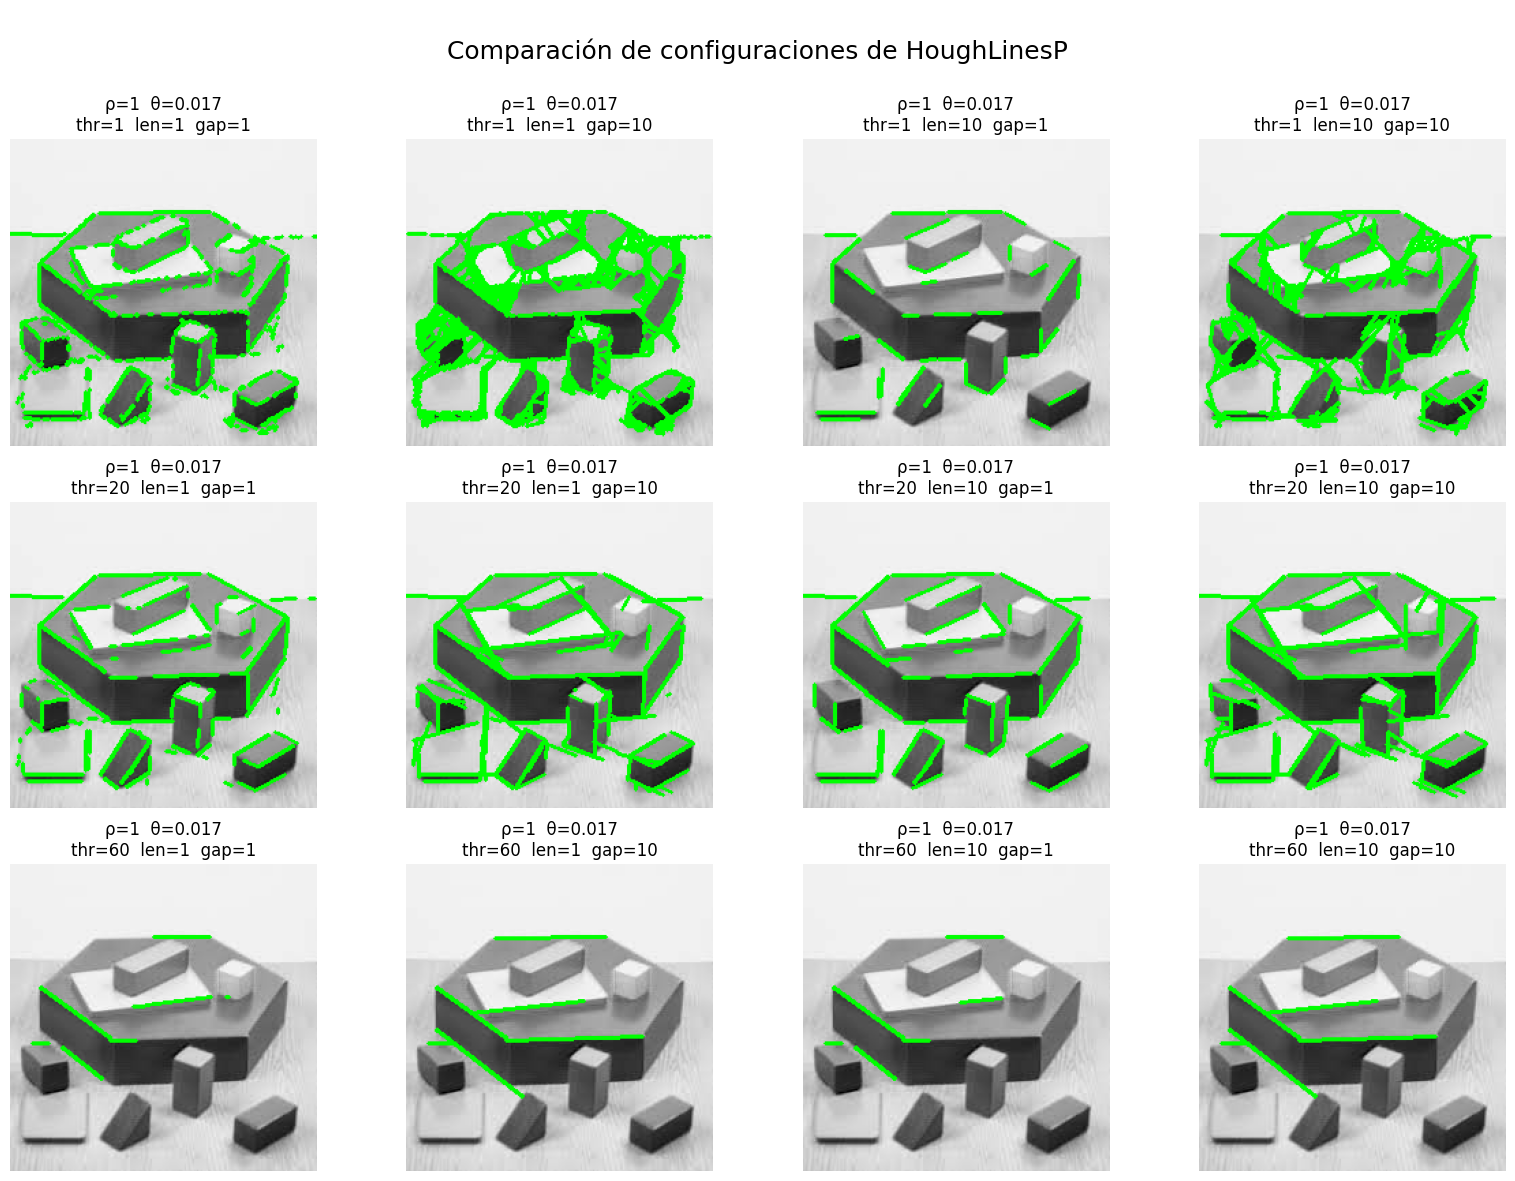

In [20]:
import matplotlib.pyplot as plt

# -------------------------------------------------------------------
# CONFIGURACIONES A PROBAR
# -------------------------------------------------------------------
rho_values            = [1] # 2]
theta_values          = [np.pi/180] #, np.pi/90]
threshold_values      = [1, 20, 60]
min_length_values     = [1, 10]
max_gap_values        = [1, 10]

# -------------------------------------------------------------------
# Imagen sobre la que probar
# -------------------------------------------------------------------

# Hacemos una copia de las imágenes originales ya que al pintar sobre ellas las estaremos sobreescribiendo
imgs_plot = load_images(imgs_path)

img = imgs_plot[0].copy()     # Imagen original

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
edges = cv2.Canny(gray, 70, 120)

# Para mostrar después los resultados
results = []

# -------------------------------------------------------------------
# BUCLE DE BARRIDO DE PARÁMETROS
# -------------------------------------------------------------------
for rho in rho_values:
    for theta in theta_values:
        for th in threshold_values:
            for min_len in min_length_values:
                for max_gap in max_gap_values:

                    # Aplicamos Hough con estos parámetros
                    lines = cv2.HoughLinesP(edges,
                                            rho=rho,
                                            theta=theta,
                                            threshold=th,
                                            minLineLength=min_len,
                                            maxLineGap=max_gap)
                    
                    # Hacemos una copia de las imágenes originales ya que al pintar sobre ellas las estaremos sobreescribiendo
                    imgs_plot = load_images(imgs_path)

                    img = imgs_plot[0].copy()     # Imagen original

                    # Copia para dibujar resultados
                    img_res = img.copy()

                    if lines is not None:
                        for x1, y1, x2, y2 in lines[:, 0]:
                            cv2.line(img_res, (x1, y1), (x2, y2), (0, 255, 0), 2)

                    # Guardamos resultado
                    results.append({
                        "rho": rho,
                        "theta": theta,
                        "threshold": th,
                        "min_len": min_len,
                        "max_gap": max_gap,
                        "image": img_res
                    })

# -------------------------------------------------------------------
# MOSTRAR RESULTADOS EN GRID
# -------------------------------------------------------------------
N = len(results)
cols = 4
rows = int(np.ceil(N / cols))

plt.figure(figsize=(16, 4 * rows))

for i, res in enumerate(results):
    plt.subplot(rows, cols, i + 1)
    plt.imshow(cv2.cvtColor(res["image"], cv2.COLOR_BGR2RGB))
    plt.title(
        f"ρ={res['rho']}  θ={round(res['theta'],3)}\n"
        f"thr={res['threshold']}  len={res['min_len']}  gap={res['max_gap']}"
    )
    plt.axis('off')

plt.suptitle("\nComparación de configuraciones de HoughLinesP\n", fontsize=18)
plt.tight_layout()
plt.show()



La comparación de distintas configuraciones de la transformada de Hough nos permite observar con claridad cómo los hiperparámetros modulan la sensibilidad y la estabilidad del detector de líneas. En los resultados obtenidos se aprecia que el parámetro más determinante es el umbral `threshold`: cuando se emplean valores bajos (por ejemplo `threshold = 1`), la imagen resultante presenta una gran cantidad de líneas, incluyendo muchas detecciones espurias en zonas con ruido o texturas complejas. La densidad de líneas aumenta notablemente y aparecen estructuras que no corresponden a bordes relevantes de los objetos presentes en la escena. Esto concuerda con lo que veníamos comentando: un umbral reducido permite que acumulaciones débiles en el espacio de Hough sean consideradas líneas válidas, lo que incrementa la sensibilidad a falsos positivos.

A medida que el umbral se incrementa (por ejemplo, `threshold = 20`), la detección se vuelve más estable y se eliminan muchos de los segmentos débiles, conservándose únicamente aquellos con mayor coherencia geométrica y contraste. Con `threshold` aún más altos (60), los resultados se vuelven todavía más depurados, mostrando únicamente las aristas principales y desapareciendo líneas menores o fragmentadas. Esto confirma que `threshold` actúa como un filtro de robustez, reduciendo el ruido estructural a costa de perder líneas si estas no son suficientemente prominentes.

En esta configuración de barrido, los parámetros `min_line_length` y `max_line_gap` toman valores más conservadores (1 y 10 respectivamente en sus extremos inferiores), lo que produce resultados visualmente más limpios en comparación con configuraciones más permisivas. Se observa claramente que con `threshold = 1` la detección es extremadamente ruidosa, generando una masa densa de líneas verdes que oscurece casi por completo la estructura del objeto. Esta sobredetección se debe a que prácticamente cualquier alineación mínima de píxeles en el espacio de Hough supera el umbral requerido.

El efecto del parámetro `max_line_gap` también es apreciable en este barrido. Cuando `gap = 10`, el algoritmo permite fusionar fragmentos de bordes moderadamente distantes, lo que produce líneas más continuas pero también incrementa el riesgo de unir segmentos que no pertenecen al mismo borde físico. Sin embargo, al mantener valores relativamente bajos en comparación con configuraciones más agresivas, el resultado es más contenido.

La fila inferior del grid, correspondiente a `threshold = 60`, muestra los resultados más depurados. En estas imágenes, únicamente se detectan las aristas principales del objeto: los bordes horizontales superiores, las aristas de los bloques y las líneas de contorno más prominentes. La detección es limpia y estructuralmente coherente, aunque algunas aristas secundarias o de menor contraste desaparecen por no alcanzar el número mínimo de votos requerido.

También se aprecia el efecto del parámetro `min_line_length`. Con `len = 1`, se permiten segmentos muy cortos, lo que puede introducir fragmentos pequeños y ruidosos. Al incrementar este valor a `len = 10`, se filtran los segmentos más cortos y solo sobreviven líneas con una extensión mínima significativa. Este filtrado geométrico complementa al umbral de votos, contribuyendo a una detección más robusta.

En conclusión, la configuración óptima para esta imagen parece encontrarse en valores de `threshold` intermedios o altos (20–60), combinados con `min_line_length` moderado (10) y `max_line_gap` bajo (1–10). Esta combinación permite detectar las aristas principales del objeto sin introducir ruido excesivo ni perder información estructural relevante.

